In [2]:
#%matplotlib 

In [32]:
import argparse
import os
import random
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from  IPython.display import HTML

# set random seed for reproducibility
manualSeed = 999

print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
torch.use_deterministic_algorithms(True)  # Needed for reproducible results

Random Seed:  999


### Create the dataset

In [18]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # Only load image files; folders and metadata files are not images.
        self.all_img_paths = [
            entry.path
            for entry in os.scandir(root_dir_path)
            if entry.name.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [19]:
project_dir = "/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba"
root_dir_path = os.path.join(project_dir, "img_align_celeba")

transformations = transforms.Compose([
    transforms.CenterCrop(178),  # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) #[-1,1]
])

loaded 202599 images


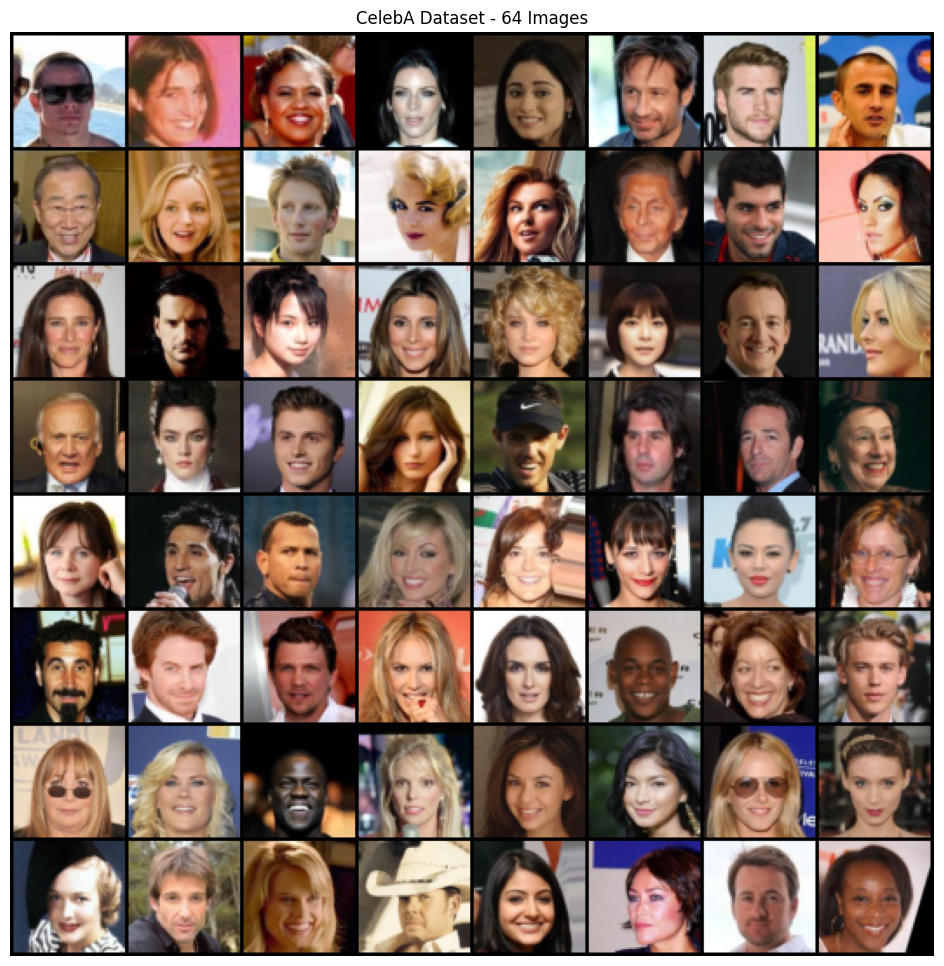

In [37]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

# Create the dataloader
dataloader = DataLoader(
    dataset,
    batch_size=128, 
    shuffle=True,
    num_workers=2
)

# Select 64 images
images = real_batch[:64]

# Create grid
grid = vutils.make_grid(
    images,
    nrow=8,
    padding=2,
    normalize=True
)

# Display grid
plt.figure(figsize=(12, 12))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("CelebA Dataset - 64 Images")
plt.show()

### Weight Initialization
all model weights shall be randomly initialized from a Normal distribution with mean=0, stdev=0.02.

In [38]:
# custom weights initialization called on ``netG`` and ``netD``
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

### Generator 

In [39]:
class Generator(nn.Module):
    def __init__(self, z=100, ngf=64, img_channels=3):
        super(Generator, self).__init__()

        self.main = nn.Sequential(
            nn.ConvTranspose2d( z, ngf * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. ``(ngf*8) x 4 x 4``
            
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. ``(ngf*4) x 8 x 8``
            
            nn.ConvTranspose2d( ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. ``(ngf*2) x 16 x 16``
            
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. ``(ngf) x 32 x 32``
            
            nn.ConvTranspose2d( ngf, img_channels, 4, 2, 1, bias=False),
            nn.Tanh()
            # state size. ``3 x 64 x 64``
        )

    def forward(self, z):
        return self.main(z)